# Animated stickman Visualizer

In [1]:
import sys
if '../' not in sys.path:
    sys.path.append('../')

In [2]:
from hmp_utils.motion.body_model_data import SMPL_KEYPOINTS, SMPL_OFFSETS, SMPL_PARENTS
from hmp_utils.motion.mocap_processor import load_mocap
from hmp_utils.motion.kinematics import ForwardKinematics
from hmp_utils.visualize.stickman_animation import pose_animation, CameraOrientation

For convenience, an example mocap sequence from AMASS is loaded. But in general, any keypoint positional data can be visualized.

In [3]:
filepath = './example_mocaps/Subject_11_F_10_poses.npz'
animation_framerate = 30

# -- load mocap --
motion = load_mocap(filepath, SMPL_KEYPOINTS)
assert motion is not None

# -- compute joint positions --
kine = ForwardKinematics(SMPL_OFFSETS['neutral'], SMPL_PARENTS)
keypoints_positions = kine.compute_fk(motion.rots, apply_root_rotation=True)

### Visualize on notebook with HTML

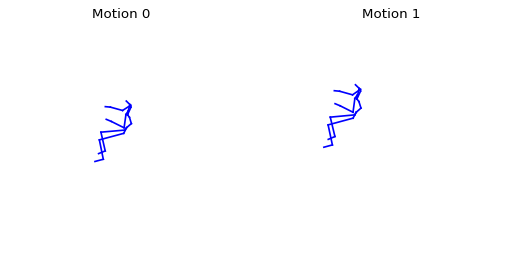

In [4]:
# List of motions keypoints positions, here the same motion
motions_list = [keypoints_positions, keypoints_positions+0.5]
subplot_ids = [0, 1]
subplot_titles = ['mocap 1', 'mocap 2']
camera_orientations = [CameraOrientation(100, 20), CameraOrientation(20, 20)]

pose_animation(motions_list, SMPL_PARENTS, subplot_ids=[0,1], camera_orientations=camera_orientations)